# Project 1 – Pass-10


## Problem Definition



Business problem: Predict whether a customer will make a successfull transaction,

Data Science problem: This is a supervised learning and classification problem. I will use the Gaussian Naive Bayes model





## Data Collection

### Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import datasets, metrics, model_selection

### File Paths

In [ ]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

### Load data

In [ ]:
#load data
transaction_df= pd.read_csv(url)

### Head

In [ ]:
# first few rows
transaction_df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Tail

In [ ]:
# last few rows
transaction_df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049999,1049999,train_1049999,0.0,2.1828,12.3805,17.5654,NaN,8.1795,NaN,NaN,...,NaN,-12.1108,NaN,10.7608,NaN,NaN,NaN,NaN,NaN,14.1690


### Shape

In [ ]:
# shape of data frame
transaction_df.shape

#output (# of rows, # of columns)

(1050000, 104)

### Size

In [ ]:
# size of data frame
transaction_df.size

109200000

### Info

In [ ]:
# display meta-data
transaction_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050000 entries, 0 to 1049999
Columns: 104 entries, Unnamed: 0 to var_100
dtypes: float64(102), int64(1), object(1)
memory usage: 833.1+ MB


## Summary statistics

### Describe

In [ ]:
# display summary statistics
transaction_df.describe()


,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
count,1.050000e+06,180000.000000,180000.000000,180000.000000,180000.000000,0.0,180000.000000,0.0,0.0,180000.000000,...,0.0,180000.000000,0.0,180000.000000,0.0,0.0,0.0,0.0,0.0,180000.000000
mean,5.249995e+05,0.100222,7.440715,15.870166,12.735619,NaN,-0.668334,NaN,NaN,1.190419,...,NaN,-3.294620,NaN,-6.727860,NaN,NaN,NaN,NaN,NaN,14.224538
std,3.031090e+05,0.300297,3.021636,3.010492,4.185923,NaN,5.968300,NaN,NaN,5.169343,...,NaN,7.418545,NaN,8.278554,NaN,NaN,NaN,NaN,NaN,0.171058
min,0.000000e+00,0.000000,-2.691700,6.299300,-1.018500,NaN,-22.748700,NaN,NaN,-15.194000,...,NaN,-29.984000,NaN,-35.211700,NaN,NaN,NaN,NaN,NaN,13.729000
25%,2.624998e+05,0.000000,5.160325,13.830400,9.664675,NaN,-4.997500,NaN,NaN,-2.571400,...,NaN,-8.757925,NaN,-12.835875,NaN,NaN,NaN,NaN,NaN,14.098900
50%,5.249995e+05,0.000000,7.350950,15.934600,12.670700,NaN,-0.560300,NaN,NaN,1.194600,...,NaN,-3.170950,NaN,-6.615100,NaN,NaN,NaN,NaN,NaN,14.226800
75%,7.874992e+05,0.000000,9.511125,18.061425,15.837300,NaN,3.632525,NaN,NaN,5.090450,...,NaN,2.043350,NaN,-0.885250,NaN,NaN,NaN,NaN,NaN,14.361800
max,1.049999e+06,1.000000,16.716500,26.079100,26.997600,NaN,18.855400,NaN,NaN,18.471400,...,NaN,21.236400,NaN,18.105600,NaN,NaN,NaN,NaN,NaN,14.743000


### Target value counts

NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [ ]:
# value_counts on target ; include nulls
transaction_df['target'].value_counts(dropna=False)

,count
target,
NaN,870000
0.0,161960
1.0,18040


In [ ]:
#normalize value counts on target ; include nulls
transaction_df['target'].value_counts(normalize=True, dropna=False)

,proportion
target,
NaN,0.828571
0.0,0.154248
1.0,0.017181


### Nulls

In [ ]:
# look for nulls
transaction_df.isnull().sum().sort_values(ascending=False)



,0
var_3,1050000
var_16,1050000
var_12,1050000
var_11,1050000
var_9,1050000
...,...
var_88,870000
var_94,870000
var_100,870000
Unnamed: 0,0


In [ ]:
# look for nulls, display relative frequency
null_sum = transaction_df.isnull().sum()
null_freq = null_sum / transaction_df.shape[0] * 100
null_freq.sort_values()

#Output- target has 82% percent null values

,0
Unnamed: 0,0.000000
ID_code,0.000000
target,82.857143
var_0,82.857143
var_1,82.857143
...,...
var_93,100.000000
var_96,100.000000
var_97,100.000000
var_98,100.000000


### Column data types

In [ ]:
# display data types
transaction_df.dtypes.sort_values()

,0
Unnamed: 0,int64
var_72,float64
var_71,float64
var_70,float64
var_69,float64
...,...
var_26,float64
var_25,float64
var_35,float64
var_100,float64


### Unique elements

In [ ]:
# number of unique elements in every column (works on the whole dataframe)
transaction_df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,1050000
ID_code,1050000
var_52,137280
var_86,134537
var_94,131746
...,...
var_93,0
var_96,0
var_97,0
var_98,0


In [ ]:
# actual unique values in one column
transaction_df['target'].unique()

array([nan,  0.,  1.])

## Data Cleaning



Backup #1

In [ ]:
# backup copy of the original data
transaction_df_backup= transaction_df.copy()


In [ ]:
# restore from backup
transaction_df=transaction_df_backup.copy()

### Drop rows with no target
  - The target has 83% nulls. Model cant learn from rows with no answer, remove them first

Selected `target` for the target and drop the rows with null values

In [ ]:
# Keep only the rows where target is not missing
transaction_df_target=transaction_df.dropna(subset=['target']).copy()
transaction_df_target.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,5,train_5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,11,train_11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,15,train_15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,19,train_19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275


In [ ]:
transaction_df_target.head(10) # this is to check

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,5,train_5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,11,train_11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,15,train_15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,19,train_19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275
22,22,train_22,0.0,6.7023,18.0127,18.4424,NaN,-5.1010,NaN,NaN,...,NaN,-4.0632,NaN,-23.8292,NaN,NaN,NaN,NaN,NaN,14.2807
29,29,train_29,0.0,11.2902,7.7553,6.6189,NaN,-7.0587,NaN,NaN,...,NaN,-14.5796,NaN,-4.8106,NaN,NaN,NaN,NaN,NaN,14.5344
33,33,train_33,0.0,4.6761,14.6116,12.4063,NaN,-9.6457,NaN,NaN,...,NaN,-8.4133,NaN,-13.9157,NaN,NaN,NaN,NaN,NaN,14.5322
35,35,train_35,0.0,10.5404,10.9793,11.0240,NaN,2.2579,NaN,NaN,...,NaN,-2.6769,NaN,10.5682,NaN,NaN,NaN,NaN,NaN,14.3515
46,46,train_46,0.0,5.6315,13.2825,20.9955,NaN,3.1402,NaN,NaN,...,NaN,8.3377,NaN,-6.9172,NaN,NaN,NaN,NaN,NaN,14.1113


### Backup #2

In [ ]:
# make backup
transaction_df_target_backup = transaction_df_target.copy()

In [ ]:
# restore from back up
transaction_df_target = transaction_df_target_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [ ]:
transaction_df_target.isnull().sum().sort_values (ascending=False) # show me where the null value are

,0
var_3,180000
var_16,180000
var_12,180000
var_11,180000
var_9,180000
...,...
var_88,0
var_86,0
var_85,0
var_94,0


In [ ]:
# Remove all the null row under target
transaction_df_target_clean =transaction_df_target.dropna(axis ='columns')
transaction_df_target_clean.isnull().sum().sort_values(ascending=False)

transaction_df_target_clean.head()



,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,3,train_3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,5,train_5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,11,train_11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,15,train_15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,19,train_19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275


In [ ]:
#DROP THE 'UNMAMED:0 and id_code, colums)
transaction_df_target_clean = transaction_df_target_clean.drop (columns=['Unnamed: 0','ID_code'])
transaction_df_target_clean

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


## Recommendations for Data Cleaning

**1. Identifier Columns**
- **Two columns:** `Unnamed: 0` is row numbers and `ID_code` is customer ID. cannot help predict anything
- **Recommendation:** Drop both columns. (I kept only `target` and `var_0` to `var_4`.)

**2. Null values:** No feature column have nulls. no action needed

**3. Target nulls:** 82% null values, rows with nulls are dropped

**4. Feature columns with high null counts:** None

**5. Medium null counts:** none

**6. Low null counts:** none

**7. Null rows:** none


## Exploratory Data Analysis ##

### Normal distribution of features:histogram

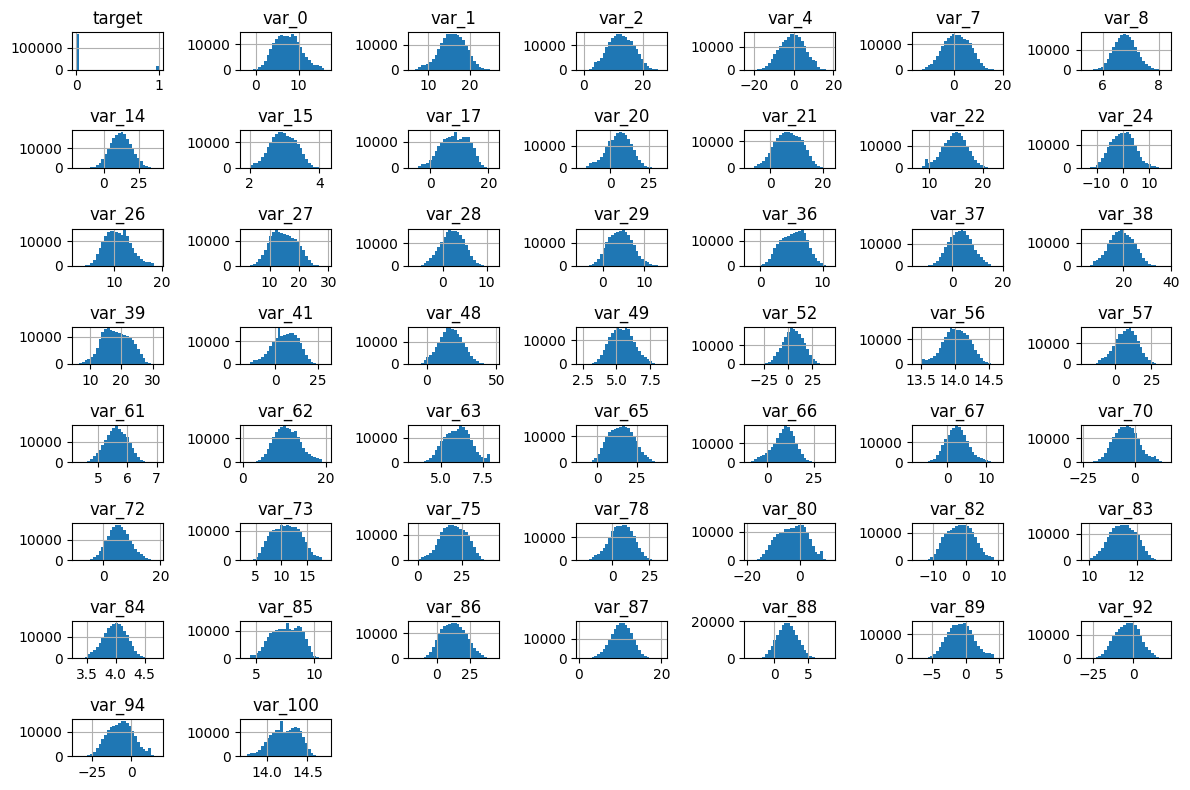

In [ ]:
# Display a histogram

transaction_df_target_clean.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


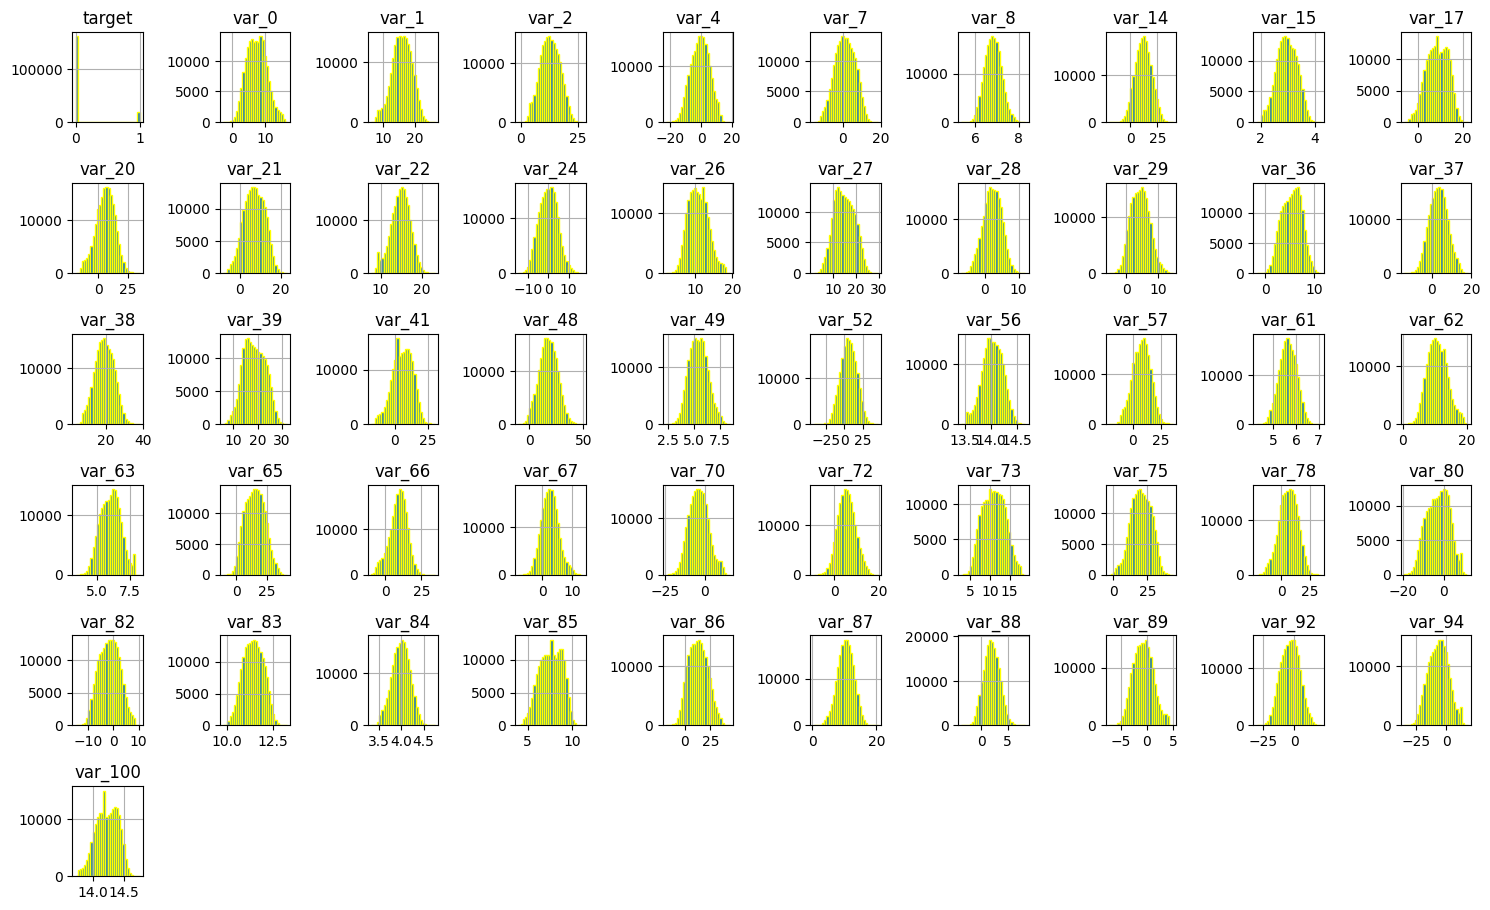

In [ ]:
# Check the distributions of the 20 features (var_0 to var_19)

transaction_df_target_clean.hist(
  figsize=(15,15), # size of the whole picture in inches(width,height)
  layout=(10,10),    # 5 rows, 4 column= 20 boxes
  bins=30,         # more bars, so the shape is clear
  edgecolor= "yellow"
)
plt.tight_layout()
plt.show()
#output- each graph look like a bell-shaped (first GNB assumption)

### Independence of features: Correlation matrix

In [ ]:
# Calculate a correlation matrix (target & features)
transaction_df_target_clean.corr()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
target,1.000000,0.045506,-0.051718,-0.046433,0.041593,-0.041987,0.052457,0.045281,-0.057373,-0.054375,...,-0.052324,-0.053733,-0.042073,0.047543,-0.063871,-0.042765,0.059306,0.040520,0.049072,-0.047005
var_0,0.045506,1.000000,-0.000892,-0.000225,-0.000269,-0.001320,0.002949,0.002901,-0.007758,-0.002799,...,-0.004960,-0.005451,-0.000716,0.004577,-0.004664,-0.001088,0.000236,0.001668,0.001837,0.001475
var_1,-0.051718,-0.000892,1.000000,0.006064,-0.000821,0.000783,-0.007127,-0.006180,-0.002585,-0.001663,...,0.004265,0.002411,0.001484,-0.003859,-0.000485,0.003141,-0.006188,0.000071,-0.003682,0.003964
var_2,-0.046433,-0.000225,0.006064,1.000000,-0.003427,-0.000108,-0.001809,-0.002786,-0.001177,0.006360,...,0.004890,0.002240,0.001980,-0.001161,0.003921,0.002087,-0.004422,-0.003418,-0.001565,0.002418
var_4,0.041593,-0.000269,-0.000821,-0.003427,1.000000,-0.002750,0.003347,0.001377,-0.004732,-0.001814,...,0.000657,-0.005267,-0.004266,-0.004179,-0.004211,-0.002330,0.000254,0.001090,-0.000468,-0.002807
var_7,-0.041987,-0.001320,0.000783,-0.000108,-0.002750,1.000000,-0.003199,-0.003588,0.002329,0.004282,...,-0.000412,0.003262,0.002574,-0.001824,0.001186,0.002811,0.001306,0.000236,-0.000568,0.004575
var_8,0.052457,0.002949,-0.007127,-0.001809,0.003347,-0.003199,1.000000,0.003472,-0.003858,-0.002727,...,-0.008394,-0.004254,-0.002446,0.001117,-0.003713,-0.003929,0.003837,0.003422,0.003204,0.000821
var_14,0.045281,0.002901,-0.006180,-0.002786,0.001377,-0.003588,0.003472,1.000000,-0.007115,-0.004249,...,-0.002214,-0.002179,-0.003054,-0.000160,-0.000504,-0.004046,0.003136,0.005715,0.001501,-0.000106
var_15,-0.057373,-0.007758,-0.002585,-0.001177,-0.004732,0.002329,-0.003858,-0.007115,1.000000,0.002467,...,0.000581,0.006633,0.004569,-0.001573,0.003251,0.003066,-0.001541,-0.003719,-0.002825,0.004247
var_17,-0.054375,-0.002799,-0.001663,0.006360,-0.001814,0.004282,-0.002727,-0.004249,0.002467,1.000000,...,0.005578,0.001237,0.000210,-0.002714,0.004149,-0.002182,-0.002642,-0.001968,-0.004100,-0.000822


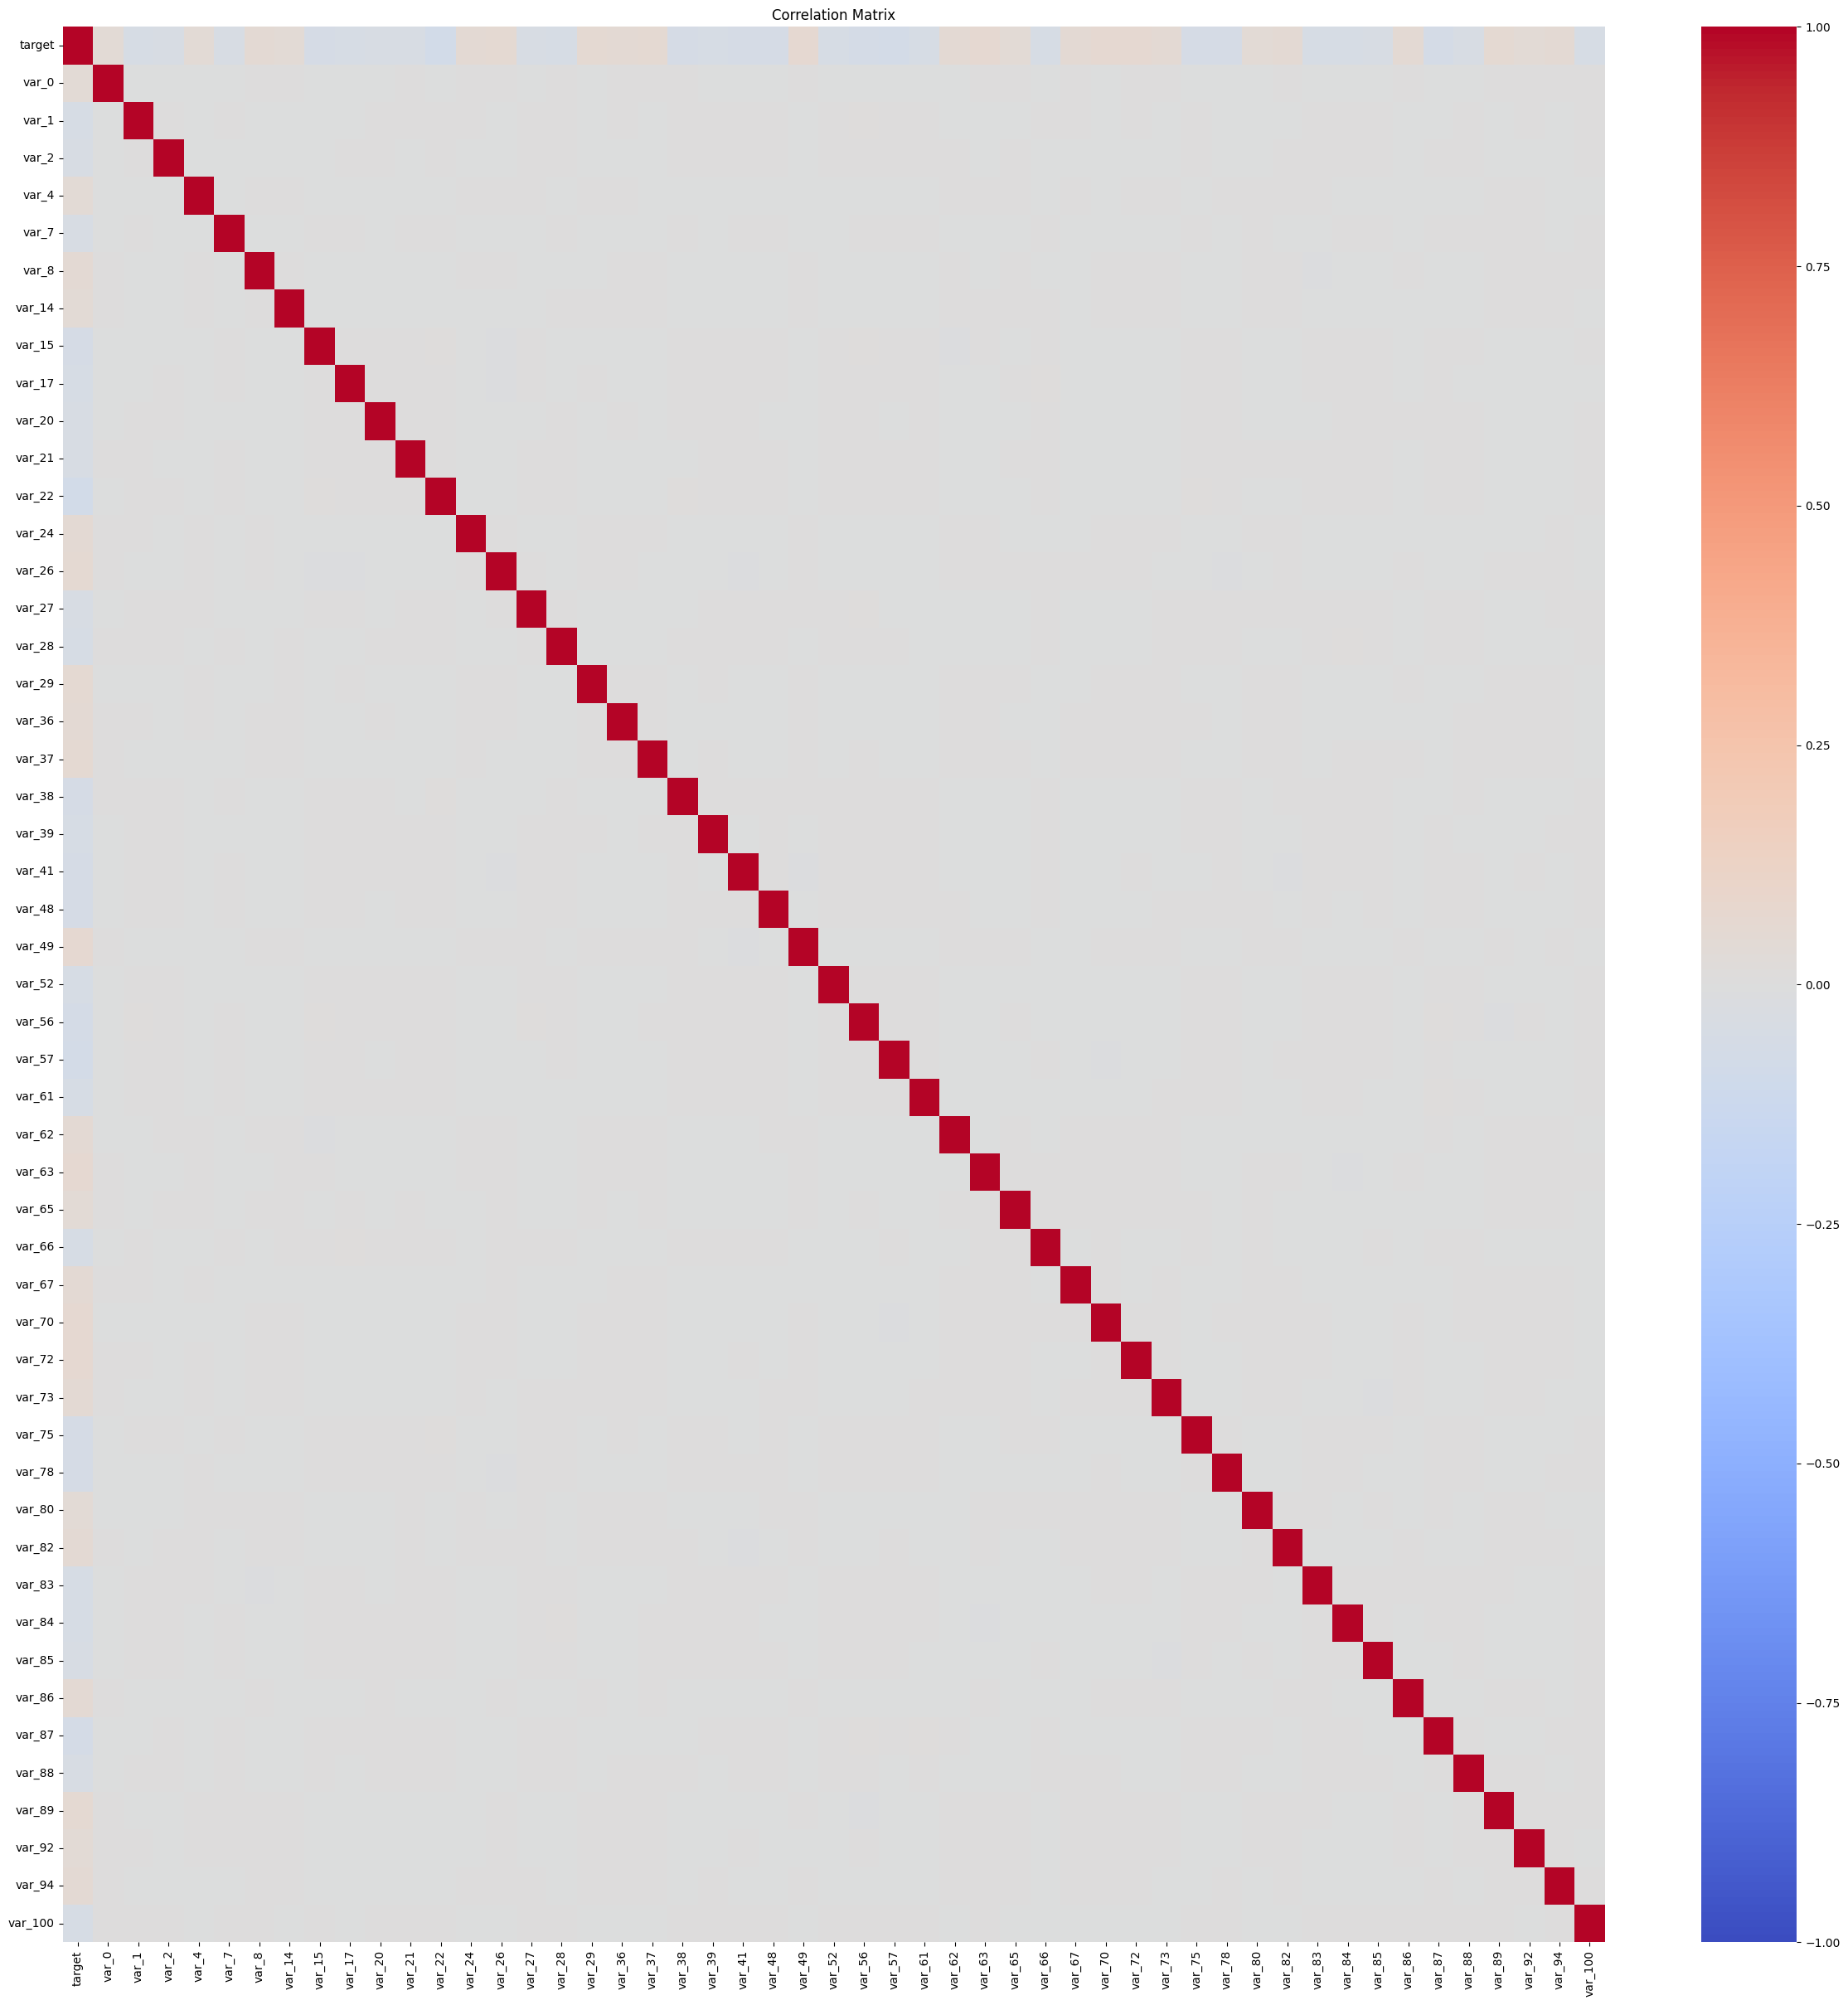

In [ ]:
# Display the correlation matrix

plt.figure(figsize=(30, 30))
sns.heatmap(transaction_df_target_clean.corr(),
            annot=False,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()


In [ ]:
# select the features
feature_cols =[] #start with an empty list to hold the features
for col in transaction_df_target_clean.columns: #look at each column name
  if col.startswith ('var_'): #if the name start with 'var_, it's a feature
    feature_cols.append(col)

print(feature_cols)
print(len(feature_cols))

['var_0', 'var_1', 'var_2', 'var_4', 'var_7', 'var_8', 'var_14', 'var_15', 'var_17', 'var_20', 'var_21', 'var_22', 'var_24', 'var_26', 'var_27', 'var_28', 'var_29', 'var_36', 'var_37', 'var_38', 'var_39', 'var_41', 'var_48', 'var_49', 'var_52', 'var_56', 'var_57', 'var_61', 'var_62', 'var_63', 'var_65', 'var_66', 'var_67', 'var_70', 'var_72', 'var_73', 'var_75', 'var_78', 'var_80', 'var_82', 'var_83', 'var_84', 'var_85', 'var_86', 'var_87', 'var_88', 'var_89', 'var_92', 'var_94', 'var_100']
50


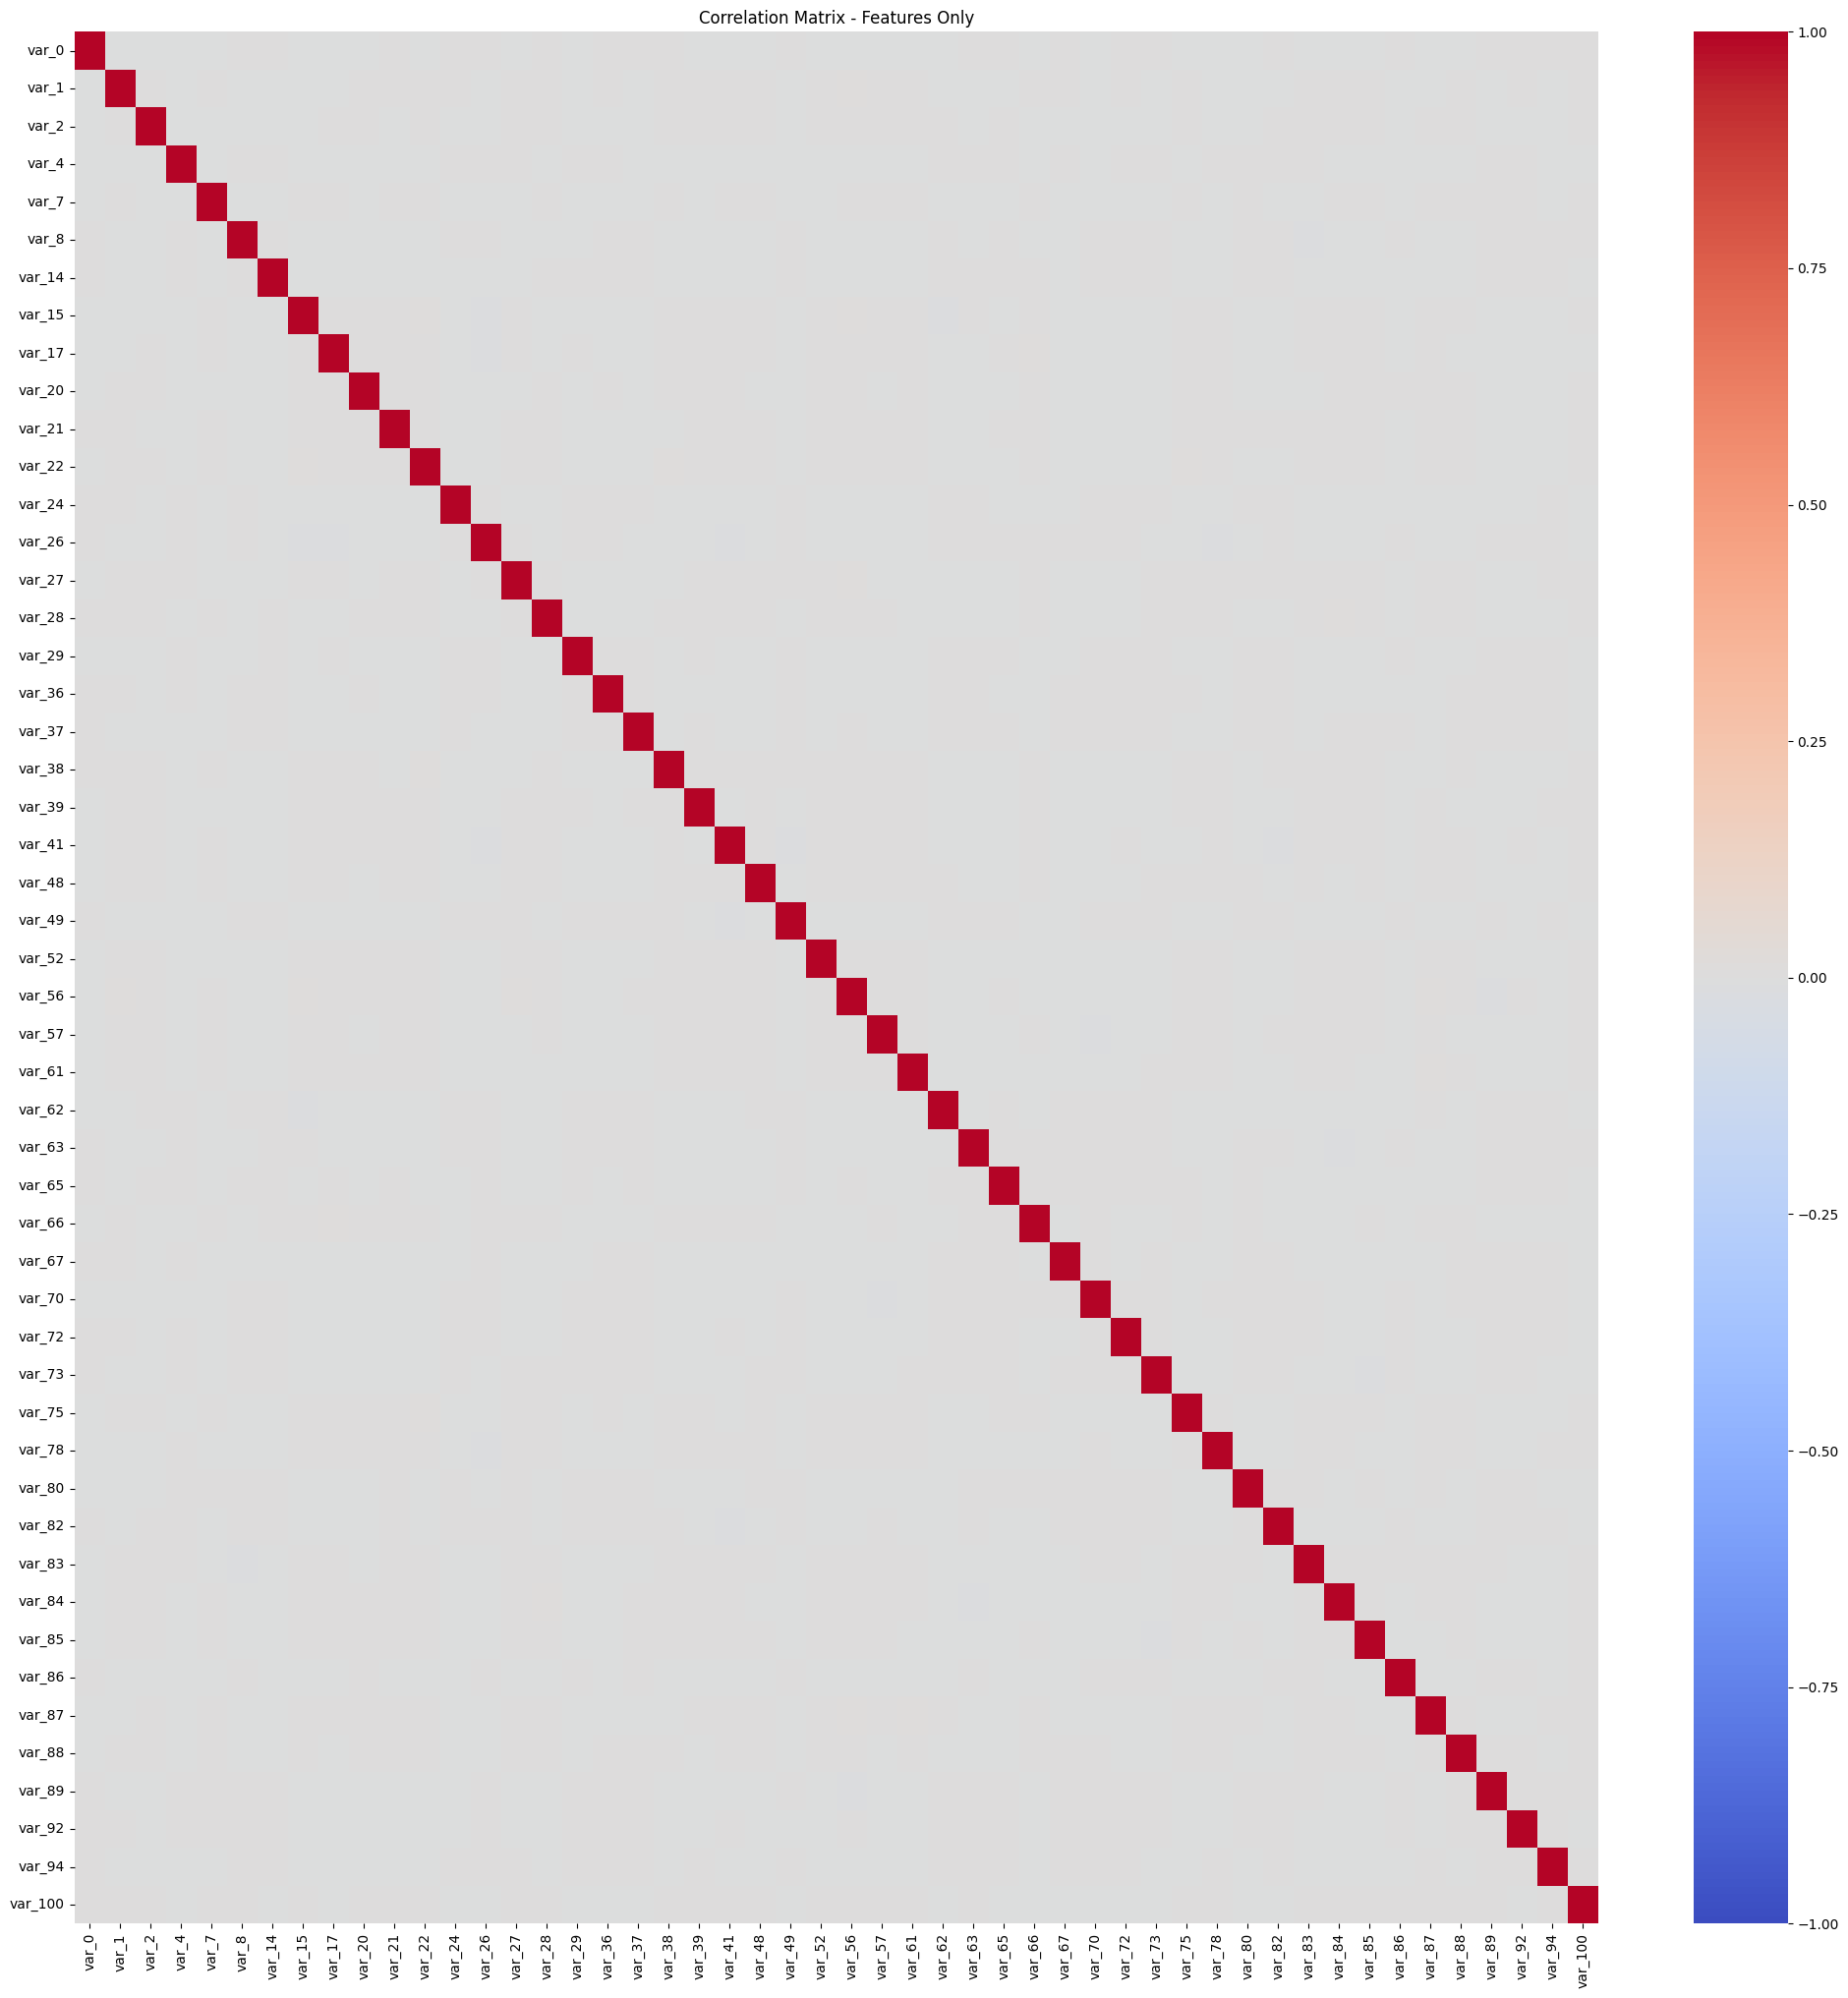

In [ ]:
# Calculate a correlation matrix (features only)
transaction_df_features_only = transaction_df_target_clean[feature_cols]
feature_corr = transaction_df_features_only.corr()

plt.figure(figsize=(25, 25))
sns.heatmap(feature_corr,
            annot=False,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white/gray = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix - Features Only')
plt.show()

#output- correlation between features are near 0
#look independent, 2nd GNB assumption


In [ ]:
# Create two data frames

# no transaction (target= 0)
transaction_df_no_success= transaction_df_target_clean[transaction_df_target_clean['target'] == 0].copy()

# successful transaction (target= 1)
transaction_df_successful= transaction_df_target_clean[transaction_df_target_clean['target'] == 1].copy()


print(type(transaction_df_successful))
print(type(transaction_df_no_success))

print(transaction_df_successful.shape)
print(transaction_df_no_success.shape)


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(18040, 51)
(161960, 51)


## Data Processing

### Single Cross-validation

In [ ]:
# Split data from into target and features
target =transaction_df_target_clean['target'].copy()
features= transaction_df_target_clean [feature_cols].copy()



In [ ]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split( features, target, test_size=0.25, random_state=42)

In [ ]:
# verify shape of each data set from Train test split
for i in (x_train, x_test,y_train,y_test):
  print(i.shape)
  print(type(i))

(135000, 50)
<class 'pandas.core.frame.DataFrame'>
(45000, 50)
<class 'pandas.core.frame.DataFrame'>
(135000,)
<class 'pandas.core.series.Series'>
(45000,)
<class 'pandas.core.series.Series'>


### Model

In [ ]:
# Create an empty GNB model
modelGNB= GaussianNB()

### Fit

In [ ]:
# Train ( fit ) the model
modelGNB.fit(x_train,y_train)

GaussianNB()

### Prediction

In [ ]:
# Make prediction using the model
pred_result= modelGNB.predict(x_test)

### Performance

In [ ]:
# Calculate the accuracy
accuracy=metrics.accuracy_score(y_test,pred_result)
accuracy*100

91.03999999999999

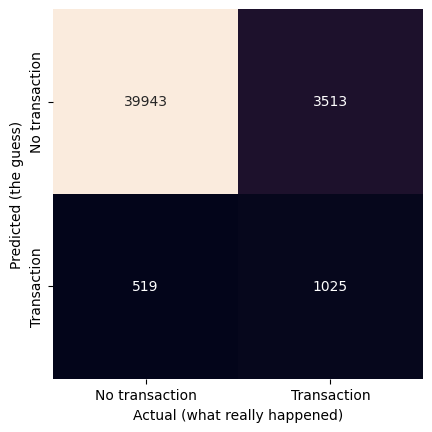

In [ ]:
# Display a confusion matrix
mat = metrics.confusion_matrix(y_test,pred_result)
names = ['No transaction', 'Transaction']
sns.heatmap(mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)

plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
#Classification report
print(metrics.classification_report(y_test, pred_result,zero_division=0 ))

#output show a warning message because model did not guess successful transactio
# zero_division=0 to remove the warning message


              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40462
         1.0       0.66      0.23      0.34      4538

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.64     45000
weighted avg       0.89      0.91      0.89     45000



### Communication of Results

The target show no transaction (‘0’) or  successful transaction (‘1’).

**Accuracy:** 90%


**Confusion matrix:**

 - 224: guessed no transaction, actually no transaction → right
  
 - 23: guessed no transaction, actually successfull transaction → wrong

 - 2: guessed sucessful transaction, actually no transaction -> wrong

 - 1: guess sucessful transaction, actually transaction ->right
  
**Classification report:**
  
  - Recall for successfull transaction: 0.04
    - The model found 1 out 24 successfull transaction.

  - Precision for successfull transaction: 0.33
    - The model said successfull transaction 3 times, right once  

  - 90% is just for the no transaction customer.

**Takeaway:** The model guessed "no transaction" for most customer transaction.

